# Paket C: Hypothesen und Resultate
Enis, Gruppe 4. Auswertung auf Halt-Ebene nach `docs/konzept.md` (Paket A).

Quellen (APA 7): The SciPy community (2026), *scipy.stats.mannwhitneyu*,
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html ;
Seabold, S., & Perktold, J. (2010), *Statsmodels: Econometric and statistical modeling
with Python*, Proceedings of the 9th Python in Science Conference.
Wetter: Quelle MeteoSchweiz; Ist-Daten: SBB/SKI. Vollstaendige Datenquellen im README.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'data/raw/.cache/matplotlib'))
import pandas as pd
from IPython.display import display, Markdown, Image
OUT = ROOT / 'docs/ergebnisse'
DB = ROOT / 'data/oev_wetter.duckdb'
pd.set_option('display.max_columns', 12)


## 1. Tests auf allen bereinigten Halten
H1: zweiseitiger Mann-Whitney-U mit Bindungskorrektur, Mittelwertdifferenz und
rang-biserialer Korrelation. Der Test vergleicht Verteilungen, die Mittelwerte
werden ergaenzend berichtet. Positive Effektstaerke bedeutet hoehere Verspaetung
bei starkem Niederschlag. Alpha = 0,05.

H2/H3: getrennte Gruppenvergleiche und OLS mit vier Spalten:
Konstante, starker Niederschlag, Gruppe, Niederschlag x Gruppe. Referenzgruppen
sind Bahn bzw. Nebenverkehrszeit. Es wird keine Stichprobe gezogen.
Klassische Standardfehler ignorieren Abhaengigkeiten derselben Fahrt; deshalb
Effekte und Richtung staerker gewichten als kleine p-Werte.

In [2]:
from analyse import analyse
tests, regression = analyse(DB)
display(tests)
display(regression)

                                  vergleich  differenz_min  rang_biserial        p_wert
                   H1: starker Niederschlag       0.220529       0.069668  0.000000e+00
Ergaenzung: Schneedecke / Frostniederschlag       0.028932       0.013514 1.535719e-186
                                        Bus       0.212245       0.062825 1.017512e-308
                                       Bahn       0.213987       0.102597 5.141499e-116
                                        HVZ       0.207970       0.079384 1.226336e-138
                                        NVZ       0.268254       0.080948  0.000000e+00
hypothese gruppe        n  interaktion_min  ci95_unten  ci95_oben       p_wert  r_quadrat
       H2    bus 11626929        -0.001742   -0.029917   0.026433 9.035402e-01   0.014742
       H3    hvz 11626929        -0.060284   -0.081635  -0.038933 3.131343e-08   0.025577


,vergleich,n_wetter,n_sonst,mittel_wetter_min,mittel_sonst_min,differenz_min,...,median_sonst_min,verspaetet_wetter_anteil,verspaetet_sonst_anteil,u,p_wert,rang_biserial
0,H1: starker Niederschlag,137355,11489574,1.613315,1.392786,0.220529,...,1.166667,0.155007,0.123590,8.440484e+11,0.000000e+00,0.069668
1,Ergaenzung: Schneedecke / Frostniederschlag,1839760,9787169,1.419745,1.390813,0.028932,...,1.166667,0.127310,0.123331,9.124689e+12,1.535719e-186,0.013514
2,Bus,120576,9935750,1.688480,1.476235,0.212245,...,1.250000,0.165439,0.134301,6.366393e+11,1.017512e-308,0.062825
3,Bahn,16779,1553824,1.073171,0.859184,0.213987,...,0.650000,0.080041,0.055099,1.437324e+10,5.141499e-116,0.102597
4,HVZ,33554,3428480,2.028599,1.820629,0.207970,...,1.483333,0.229123,0.191635,6.208572e+10,1.226336e-138,0.079384
5,NVZ,103801,8061094,1.479073,1.210819,0.268254,...,1.050000,0.131049,0.094649,4.522414e+11,0.000000e+00,0.080948


,hypothese,gruppe,n,interaktion_min,ci95_unten,ci95_oben,p_wert,r_quadrat
0,H2,bus,11626929,-0.001742,-0.029917,0.026433,9.035402e-01,0.014742
1,H3,hvz,11626929,-0.060284,-0.081635,-0.038933,3.131343e-08,0.025577


## 2. H1: Niederschlag und Verspaetung
Starker Niederschlag: 1,613 statt 1,393 Minuten, also +0,221 Minuten (13,2 Sekunden).
Rang-biserial r = 0,070: kleiner Zusammenhang. Verspaetete Halte (>=3 Min.) nehmen
von 12,36% auf 15,50% zu. H1 wird fuer Niederschlag in der erwarteten Richtung gestuetzt.
Ein numerisch gespeicherter p-Wert von 0 bedeutet Unterlauf, nicht exakt null.

Schneedecke/Frostniederschlag ergaenzend: +0,029 Minuten, r = 0,014.
Die Definition wechselt je nach Schneeparameter; daraus folgt kein belastbarer
Nachweis eines isolierten aktuellen Schneefalleffekts.

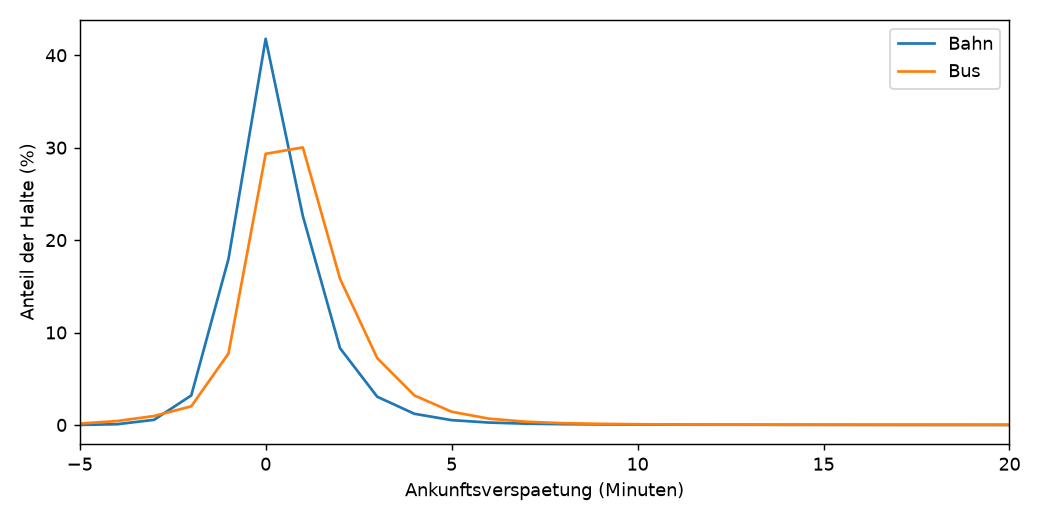

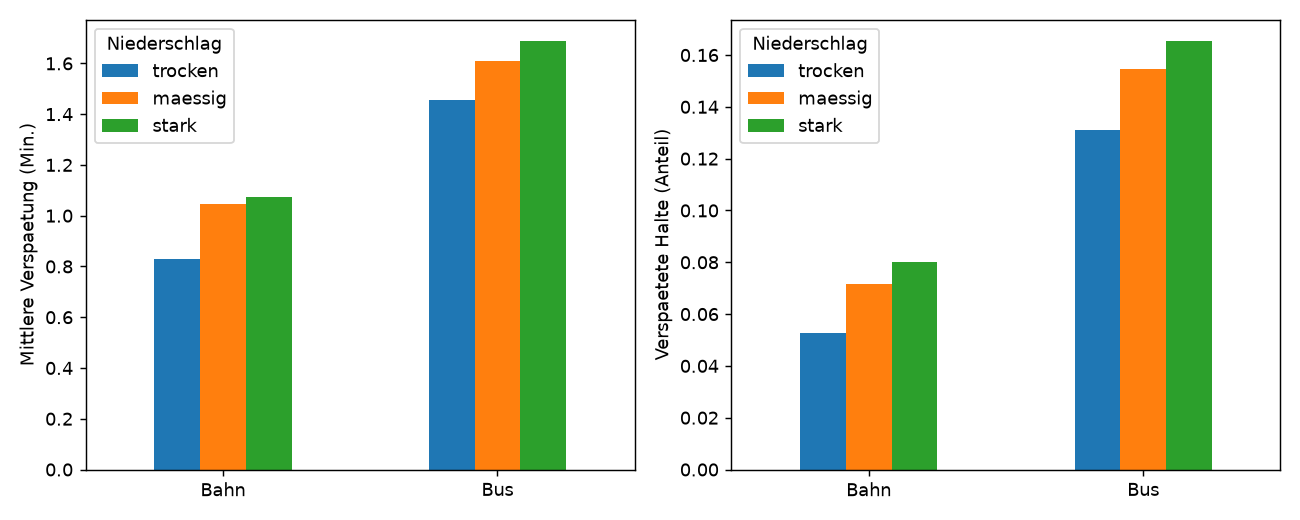

In [3]:
display(Image(filename=str(OUT / 'verspaetungsverteilung.png')))
display(Image(filename=str(OUT / 'wetter_verkehrsmittel.png')))

## 3. H2 und H3: Verstaerkt sich der Zusammenhang?
**H2 nicht gestuetzt:** Bus +0,212 Min., Bahn +0,214 Min. Die Interaktion ist
-0,0017 Min., 95%-KI [-0,0299; 0,0264], p=0,904.

**H3 nicht gestuetzt:** HVZ +0,208 Min., NVZ +0,268 Min. Interaktion -0,0603 Min.,
95%-KI [-0,0816; -0,0389], p<0,001. Die Richtung ist umgekehrt.
Die hoehere allgemeine Verspaetung in der HVZ ist keine Verstaerkung des Wettereffekts.

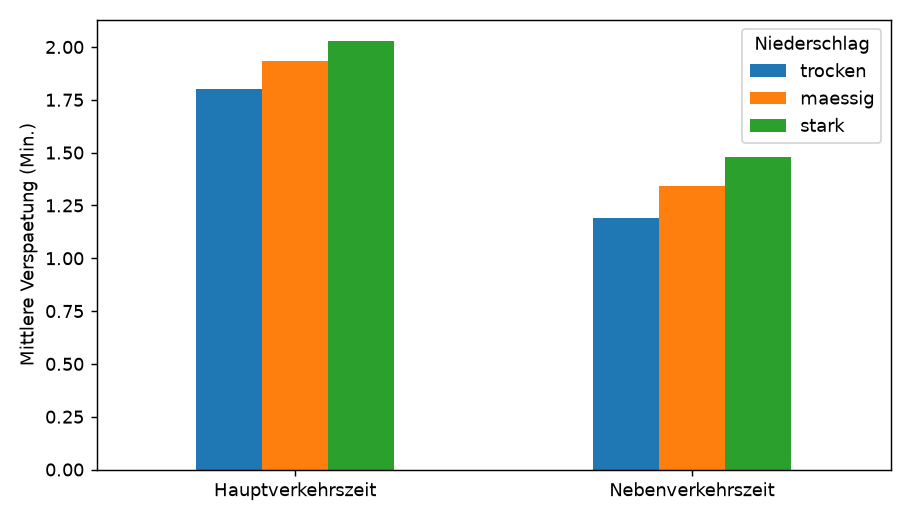

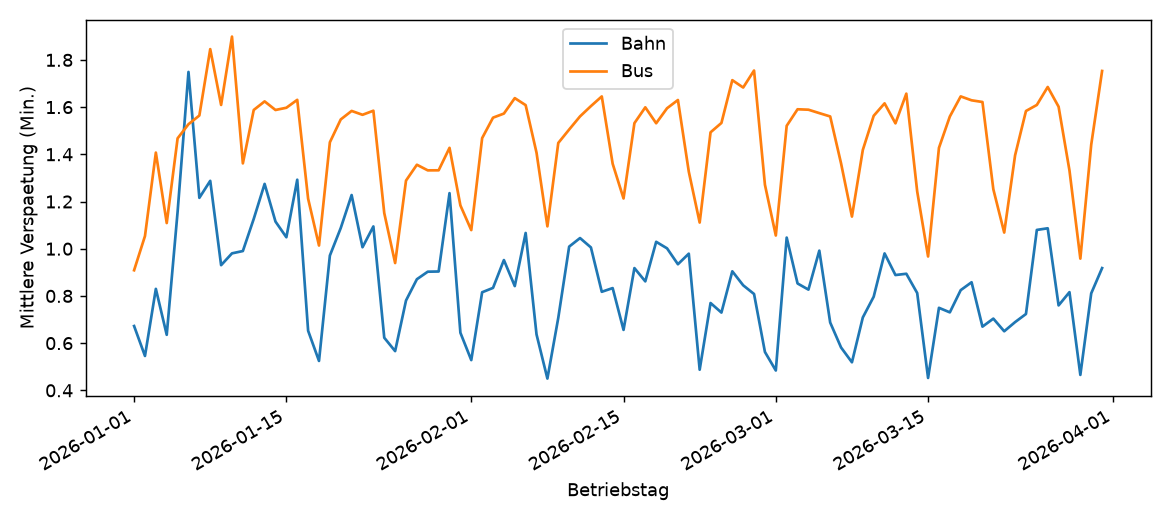

In [4]:
display(Image(filename=str(OUT / 'wetter_hvz.png')))
display(Image(filename=str(OUT / 'zeitreihe.png')))

## 4. Antwort und Grenzen
Starker Niederschlag haengt in diesem Quartal mit etwas mehr Ankunftsverspaetung
zusammen. Ein staerkerer Effekt beim Bus oder in der HVZ zeigt sich nicht.
Das sind Zusammenhaenge, keine Kausalitaet.

- Nur Januar-Maerz 2026; andere Jahreszeiten/Jahre sind nicht abgedeckt.
- Abhaengige Halte und unkontrollierte Ursachen koennen Signifikanz verzerren.
- REAL-Anteile unterscheiden sich zwischen Bahn und Bus. Ausfaelle und Extreme
  wurden ausgeschlossen; das ist keine Gesamtmessung der Zuverlaessigkeit.
- Stationen liegen nicht am Halt; 47 Haltestellen sind nicht zugeordnet.
- Schneehoehe ist keine aktuelle Schneefallmessung; Frostniederschlag ist ein Proxy.
- Gesetzliche kantonale Feiertage sind enthalten, kommunale Sonderfaelle,
  betriebliche Ruhetage und Schulferien nicht.

Fertige Uebergabe und Folienvorlage: `docs/uebergabe_paket_c.md`.
Reproduzierbare Befehle und Ergebnisablage stehen im README.